In [1]:
import nltk 
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np
import random

In [2]:
import pandas as pd

df = pd.read_csv("hf://datasets/gsri-18/ISEAR-dataset-complete/ISEAR_dataset_complete.csv")
df = df.drop(columns=["Unnamed: 2"])
content = df["content"]
print(content.head())
emotions = df["emotion"].unique()

0    On days when I feel close to my partner and ot...
1    Every time I imagine that someone I love or I ...
2    When I had been obviously unjustly treated and...
3    When I think about the short time that we live...
4    At a gathering I found myself involuntarily si...
Name: content, dtype: str


In [3]:
# Dataset statistics before tokenization
emotions_unique = df["emotion"].unique()
print("Dataset statistics before tokenization for each unique emotion:")
print()
for emotion in emotions_unique:
    subset = df[df["emotion"] == emotion]
    N = len(subset["emotion"])
    print(f"{emotion} has {N} occurences, {round(N/len(df["emotion"]) * 100, 2)}%")
    average_length = subset["content"].str.len().mean()
    print(f"{emotion} has an average length of {average_length:.2f} characters")
    print()


Dataset statistics before tokenization for each unique emotion:

joy has 1092 occurences, 14.53%
joy has an average length of 103.14 characters

fear has 1076 occurences, 14.32%
fear has an average length of 123.96 characters

anger has 1079 occurences, 14.36%
anger has an average length of 130.65 characters

sadness has 1082 occurences, 14.4%
sadness has an average length of 103.93 characters

disgust has 1066 occurences, 14.18%
disgust has an average length of 114.61 characters

shame has 1071 occurences, 14.25%
shame has an average length of 116.73 characters

guilt has 1050 occurences, 13.97%
guilt has an average length of 124.89 characters



In [4]:
# Representation 1: Tokenization
tokens = []
for element in df["content"]:
    tokenized_sentence = word_tokenize(element)
    tokens.append(tokenized_sentence)
df["tokens"] = tokens


In [5]:
df.head(5)
# print avarage token length of sentence here.

,emotion,content,tokens
0,joy,On days when I feel close to my partner and ot...,"[On, days, when, I, feel, close, to, my, partn..."
1,fear,Every time I imagine that someone I love or I ...,"[Every, time, I, imagine, that, someone, I, lo..."
2,anger,When I had been obviously unjustly treated and...,"[When, I, had, been, obviously, unjustly, trea..."
3,sadness,When I think about the short time that we live...,"[When, I, think, about, the, short, time, that..."
4,disgust,At a gathering I found myself involuntarily si...,"[At, a, gathering, I, found, myself, involunta..."


In [6]:
# Representation 2: Bag of words
vectorizer = CountVectorizer(analyzer=lambda tokens: tokens)

bag_matrix = vectorizer.fit_transform(df["tokens"].tolist())

bag_df = pd.DataFrame(bag_matrix.toarray(),
                      columns=vectorizer.get_feature_names_out(),
                      index=df.index
)

print(bag_df.head(5))

   !  $  %  &  '  ''  'd  'll  'm  're  ...  yr.  yrs  yukky  zero  \
0  0  0  0  0  0   0   0    0   0    0  ...    0    0      0     0   
1  0  0  0  0  0   0   0    0   0    0  ...    0    0      0     0   
2  0  0  0  0  0   0   0    0   0    0  ...    0    0      0     0   
3  0  0  0  0  0   0   0    0   0    0  ...    0    0      0     0   
4  0  0  0  0  0   0   0    0   0    0  ...    0    0      0     0   

   zig-zagging  zip  zipper  zombies  zone  zoophiliac  
0            0    0       0        0     0           0  
1            0    0       0        0     0           0  
2            0    0       0        0     0           0  
3            0    0       0        0     0           0  
4            0    0       0        0     0           0  

[5 rows x 10173 columns]


In [7]:
# Representation 3: Bigrams

bigrams = []
for sentence in df["tokens"]:
    bigrams_per_sentence = []
    for i in range(len(sentence) - 1):
        bigram = sentence[i] + " " + sentence[i+1]
        bigrams_per_sentence.append(bigram)
    bigrams.append(bigrams_per_sentence)
df["bigrams"] = bigrams

In [8]:
# Representation 4: Trigrams

trigrams = []
for sentence in df["tokens"]:
    trigrams_per_sentence = []
    for i in range(len(sentence) - 2):
        trigram = sentence[i] + " " + sentence[i+1] + " " + sentence[i+2]
        trigrams_per_sentence.append(trigram)
    trigrams.append(trigrams_per_sentence)
df["trigrams"] = trigrams

In [9]:
print(df["trigrams"][0])

['On days when', 'days when I', 'when I feel', 'I feel close', 'feel close to', 'close to my', 'to my partner', 'my partner and', 'partner and other', 'and other friends', 'other friends .', 'friends . When', '. When I', 'When I feel', 'I feel at', 'feel at peace', 'at peace with', 'peace with myself', 'with myself and', 'myself and also', 'and also experience', 'also experience a', 'experience a close', 'a close contact', 'close contact with', 'contact with people', 'with people whom', 'people whom I', 'whom I regard', 'I regard greatly', 'regard greatly .']


In [10]:
# Architecture 1: Log-Linear
import itertools
nltk.download("punkt_tab")

corpus = " ".join(df["content"].fillna("").astype(str))

vocab = sorted(set(word_tokenize(corpus)))
token_to_id = {token: i for i, token in enumerate(vocab)}

class Encoder:
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

def cross_validation_split(pairs, k, seed=0):
    """
    Shuffles a list of labelled texts and splits the result into k folds.
    
    pairs: lists of tuples (text, label)
    k: number of folds
    seed: for reproducible shuffling
    """
    
    # Shuffle the pairs
    random.seed(seed)
    pairs = list(pairs)
    ids = list(range(len(pairs)))
    random.shuffle(ids)

    # Split without coercing (text, int) tuples into a string array
    ids_parts = np.array_split(np.array(ids, dtype=object), k)
    
    # Create a dictionary to store the training and validation sets for each fold
    cross_validation_sets = {}
    for i in range(k):
        validation_set = [pairs[j] for j in ids_parts[i]] 
        training_ids = list(itertools.chain.from_iterable(part for k, part in enumerate(ids_parts) if k != i))
        training_set = [pairs[j] for j in training_ids]
        cross_validation_sets[i] = {
            "training": training_set, 
            "validation": validation_set, 
            'training_ids': training_ids,   # these are not often needed, but we return it just in case
            'validation_ids': ids_parts[i]  # these are not often needed, but we return it just in case
        }

    return cross_validation_sets

my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

# for seed in my_seeds:  
#     my_cross_validation_sets.append(
#         cross_validation_split(
#             # we pair the texts with their labels
#             pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
#             k=num_folds,
#             seed=seed
#         )
#     )

class TokenIndicator(Encoder):
    def __init__(self, token_to_id):
        self.token_to_id = token_to_id

    def __len__(self):
        return len(self.token_to_id)

    def __call__(self, x: str) -> np.ndarray:
        vector = np.zeros(len(self), dtype=np.float32)

        for token in set(word_tokenize(x)):
            token_id = self.token_to_id.get(token)
            if token_id is not None:
                vector[token_id] = 1

        return vector
    
token_indicator_encoder = TokenIndicator(token_to_id)
doc_repr = token_indicator_encoder(corpus)

print(len(doc_repr))
print(doc_repr.sum())

[nltk_data] Downloading package punkt_tab to /home/colin/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


10176
10176.0


In [11]:
import os
results_folder = "../Data/Results"
os.makedirs(results_folder, exist_ok=True)

In [12]:
# Architecture 2: Single hidden layer MLP
import smlp

class CountVectorizerEncoder(Encoder):
    def __init__(self, vectorizer):
        self.vectorizer = vectorizer

    def __len__(self):
        return len(self.vectorizer.vocabulary_)

    def __call__(self, x: str) -> np.ndarray:
        return self.vectorizer.transform([x]).toarray().ravel()

labels = sorted(df["emotion"].unique())
pairs = [(content, labels.index(emotion)) for content, emotion in zip(df["content"], df["emotion"])]
cv = cross_validation_split(pairs, k=num_folds, seed=0)

# Settings for encoders for token indicator, BOW and unigrams + trigrams (capped due to memory issues).
encoder_configs = {
    "token-indicator": {
        "binary": True,
        "ngram_range": (1, 1),
    },
    "bag-of-words": {
        "binary": False,
        "ngram_range": (1, 1),
    },
    "bigrams-and-trigrams": {
        "binary": False,
        "ngram_range": (1, 2),
        "max_features": 20000
    },
}

results = {name: [] for name in encoder_configs}
mean_accuracy = {}
# For each encoder run the model with hidden dim of 128 with cross validation.
for encoder_name, config in encoder_configs.items():
    for fold in cv:
        print(encoder_name)
        training = cv[fold]["training"]
        validation = cv[fold]["validation"]

        vectorizer = CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            **config,
        )
        print("Fitting vectorizer")
        vectorizer.fit([content for content, label in training])
        print("Vocabulary size:", len(vectorizer.vocabulary_))
        print("Training MLP")
        encoder = CountVectorizerEncoder(vectorizer)

        metrics, best_epoch, best_pred = smlp.train_neural_network_model(
            training,
            validation,
            num_classes=len(labels),
            encoder=encoder,
            save_to=f"{results_folder}/mlp_{encoder_name}_{fold}_test",
            num_epochs=10,
        )

        best_val_acc_this_fold = max(epoch_data["val_metrics"]["accuracy"] for epoch_data in metrics)
        mean_accuracy[f"{encoder_name}"] = np.mean(best_val_acc_this_fold)
print(mean_accuracy)


token-indicator
Fitting vectorizer
Vocabulary size: 8343
Training MLP
Transforming documents...
Document transformation done! Time taken: 2.909 seconds
Dataloader done! Time taken: 0.351 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

/home/colin/Downloads/nlp1-student-main/NLP-Classification-Project/Code/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:249.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/colin/Downloads/nlp1-student-main/NLP-Classification-Project/Code/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:916.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 1.7913 | train acc: 0.4118 | val loss: 1.5576 | val acc: 0.5040
Epoch 02 | train loss: 1.1763 | train acc: 0.6690 | val loss: 1.2314 | val acc: 0.5705
Epoch 03 | train loss: 0.7614 | train acc: 0.7919 | val loss: 1.1675 | val acc: 0.5851
Epoch 04 | train loss: 0.5331 | train acc: 0.8601 | val loss: 1.1976 | val acc: 0.5824
Epoch 05 | train loss: 0.3927 | train acc: 0.9007 | val loss: 1.2446 | val acc: 0.5778
Epoch 06 | train loss: 0.2984 | train acc: 0.9280 | val loss: 1.3005 | val acc: 0.5745
Epoch 07 | train loss: 0.2314 | train acc: 0.9471 | val loss: 1.3627 | val acc: 0.5758
Epoch 08 | train loss: 0.1861 | train acc: 0.9584 | val loss: 1.4488 | val acc: 0.5698
Epoch 09 | train loss: 0.1491 | train acc: 0.9696 | val loss: 1.5187 | val acc: 0.5718
Epoch 10 | train loss: 0.1223 | train acc: 0.9764 | val loss: 1.5901 | val acc: 0.5685
Training done! Time taken: 15.681 seconds
token-indicator
Fitting vectorizer
Vocabulary size: 8399
Training MLP
Transforming docum

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.8053 | train acc: 0.3912 | val loss: 1.5594 | val acc: 0.5376
Epoch 02 | train loss: 1.1847 | train acc: 0.6720 | val loss: 1.2249 | val acc: 0.5768
Epoch 03 | train loss: 0.7626 | train acc: 0.7870 | val loss: 1.1780 | val acc: 0.5802
Epoch 04 | train loss: 0.5383 | train acc: 0.8573 | val loss: 1.1832 | val acc: 0.5815
Epoch 05 | train loss: 0.3986 | train acc: 0.9024 | val loss: 1.2217 | val acc: 0.5855
Epoch 06 | train loss: 0.3059 | train acc: 0.9288 | val loss: 1.2757 | val acc: 0.5848
Epoch 07 | train loss: 0.2406 | train acc: 0.9448 | val loss: 1.3317 | val acc: 0.5875
Epoch 08 | train loss: 0.1931 | train acc: 0.9571 | val loss: 1.3941 | val acc: 0.5775
Epoch 09 | train loss: 0.1563 | train acc: 0.9697 | val loss: 1.4665 | val acc: 0.5669
Epoch 10 | train loss: 0.1309 | train acc: 0.9756 | val loss: 1.5341 | val acc: 0.5589
Training done! Time taken: 13.816 seconds
token-indicator
Fitting vectorizer
Vocabulary size: 8413
Training MLP
Transforming docum

... (22 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6802 | train acc: 0.4409 | val loss: 1.3552 | val acc: 0.5835
Epoch 02 | train loss: 0.8357 | train acc: 0.7800 | val loss: 1.1359 | val acc: 0.6088
Epoch 03 | train loss: 0.3829 | train acc: 0.9207 | val loss: 1.1490 | val acc: 0.5988
Epoch 04 | train loss: 0.1930 | train acc: 0.9687 | val loss: 1.2067 | val acc: 0.5828
Epoch 05 | train loss: 0.1084 | train acc: 0.9850 | val loss: 1.2902 | val acc: 0.5782
Epoch 06 | train loss: 0.0684 | train acc: 0.9942 | val loss: 1.3540 | val acc: 0.5888
Epoch 07 | train loss: 0.0452 | train acc: 0.9967 | val loss: 1.4073 | val acc: 0.5768
Epoch 08 | train loss: 0.0339 | train acc: 0.9968 | val loss: 1.4718 | val acc: 0.5775
Epoch 09 | train loss: 0.0266 | train acc: 0.9977 | val loss: 1.5237 | val acc: 0.5755
Epoch 10 | train loss: 0.0223 | train acc: 0.9980 | val loss: 1.5654 | val acc: 0.5742
Training done! Time taken: 24.314 seconds
bigrams-and-trigrams
Fitting vectorizer
Vocabulary size: 20000
Training MLP
Transforming

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.7036 | train acc: 0.4252 | val loss: 1.3638 | val acc: 0.5715
Epoch 02 | train loss: 0.8608 | train acc: 0.7685 | val loss: 1.1302 | val acc: 0.6055
Epoch 03 | train loss: 0.3893 | train acc: 0.9162 | val loss: 1.1318 | val acc: 0.6028
Epoch 04 | train loss: 0.1957 | train acc: 0.9664 | val loss: 1.1765 | val acc: 0.6001
Epoch 05 | train loss: 0.1115 | train acc: 0.9852 | val loss: 1.2396 | val acc: 0.5975
Epoch 06 | train loss: 0.0709 | train acc: 0.9920 | val loss: 1.2847 | val acc: 0.5968
Epoch 07 | train loss: 0.0491 | train acc: 0.9942 | val loss: 1.3466 | val acc: 0.6008
Epoch 08 | train loss: 0.0346 | train acc: 0.9970 | val loss: 1.3963 | val acc: 0.5935
Epoch 09 | train loss: 0.0269 | train acc: 0.9968 | val loss: 1.4377 | val acc: 0.5928
Epoch 10 | train loss: 0.0222 | train acc: 0.9972 | val loss: 1.4777 | val acc: 0.5955
Training done! Time taken: 24.119 seconds
{'token-indicator': np.float64(0.6081170991350632), 'bag-of-words': np.float64(0.6094477

In [13]:
# Architecture 3: Modified MLP - 2 hidden layers

import smlp_mod
class CountVectorizerEncoder(Encoder):
    def __init__(self, vectorizer):
        self.vectorizer = vectorizer

    def __len__(self):
        return len(self.vectorizer.vocabulary_)

    def __call__(self, x: str) -> np.ndarray:
        return self.vectorizer.transform([x]).toarray().ravel()

labels = sorted(df["emotion"].unique())
pairs = [(content, labels.index(emotion)) for content, emotion in zip(df["content"], df["emotion"])]
cv = cross_validation_split(pairs, k=num_folds, seed=0)

encoder_configs = {
    "token-indicator": {
        "binary": True,
        "ngram_range": (1, 1),
    },
    "bag-of-words": {
        "binary": False,
        "ngram_range": (1, 1),
    },
    "bigrams-and-trigrams": {
        "binary": False,
        "ngram_range": (1, 2),
        "max_features": 50000
    },
}

results = {name: [] for name in encoder_configs}

encoder_accuracy = {}
for encoder_name, config in encoder_configs.items():
    mean_accuracy = []
    for fold in cv:
        print(encoder_name)
        training = cv[fold]["training"]
        validation = cv[fold]["validation"]

        vectorizer = CountVectorizer(
            tokenizer=word_tokenize,
            token_pattern=None,
            **config,
        )
        vectorizer.fit([content for content, label in training])
        print("Vocabulary size:", len(vectorizer.vocabulary_))
        encoder = CountVectorizerEncoder(vectorizer)

        metrics, best_epoch, best_pred = smlp_mod.train_neural_network_model(
            training,
            validation,
            num_classes=len(labels),
            encoder=encoder,
            save_to=f"{results_folder}/mlp_{encoder_name}_{fold}_test",
            num_epochs=10,
        )

        results[encoder_name].append(
            {
                "metrics": metrics,
                "best_epoch": best_epoch,
                "best_pred": best_pred,
            }
        )

        best_val_acc_this_fold = max(epoch_data["val_metrics"]["accuracy"] for epoch_data in metrics)
        mean_accuracy.append(best_val_acc_this_fold)
    encoder_accuracy[f"{encoder_name}"] = np.mean(mean_accuracy)



token-indicator
Vocabulary size: 8343
Transforming documents...
Document transformation done! Time taken: 2.674 seconds
Dataloader done! Time taken: 0.329 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6659 | train acc: 0.3560 | val loss: 1.2978 | val acc: 0.5426
Epoch 02 | train loss: 1.1587 | train acc: 0.5968 | val loss: 1.2684 | val acc: 0.5419
Epoch 03 | train loss: 0.9392 | train acc: 0.6760 | val loss: 1.2604 | val acc: 0.5472
Epoch 04 | train loss: 0.7774 | train acc: 0.7369 | val loss: 1.2868 | val acc: 0.5545
Epoch 05 | train loss: 0.6923 | train acc: 0.7693 | val loss: 1.3290 | val acc: 0.5519
Epoch 06 | train loss: 0.6010 | train acc: 0.8006 | val loss: 1.3301 | val acc: 0.5632
Epoch 07 | train loss: 0.5847 | train acc: 0.8051 | val loss: 1.3402 | val acc: 0.5665
Epoch 08 | train loss: 0.5190 | train acc: 0.8283 | val loss: 1.3953 | val acc: 0.5545
Epoch 09 | train loss: 0.4994 | train acc: 0.8360 | val loss: 1.4141 | val acc: 0.5532
Epoch 10 | train loss: 0.4793 | train acc: 0.8446 | val loss: 1.4539 | val acc: 0.5705
Training done! Time taken: 11.379 seconds
token-indicator
Vocabulary size: 8399
Transforming documents...
Document transformation 

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6802 | train acc: 0.3484 | val loss: 1.2856 | val acc: 0.5429
Epoch 02 | train loss: 1.1809 | train acc: 0.5749 | val loss: 1.2333 | val acc: 0.5502
Epoch 03 | train loss: 0.9276 | train acc: 0.6744 | val loss: 1.2290 | val acc: 0.5629
Epoch 04 | train loss: 0.7825 | train acc: 0.7311 | val loss: 1.2622 | val acc: 0.5496
Epoch 05 | train loss: 0.6860 | train acc: 0.7755 | val loss: 1.3092 | val acc: 0.5635
Epoch 06 | train loss: 0.6044 | train acc: 0.7989 | val loss: 1.3733 | val acc: 0.5589
Epoch 07 | train loss: 0.5482 | train acc: 0.8177 | val loss: 1.4146 | val acc: 0.5529
Epoch 08 | train loss: 0.5092 | train acc: 0.8369 | val loss: 1.3880 | val acc: 0.5496
Epoch 09 | train loss: 0.4644 | train acc: 0.8485 | val loss: 1.5007 | val acc: 0.5496
Epoch 10 | train loss: 0.4537 | train acc: 0.8517 | val loss: 1.4542 | val acc: 0.5536
Training done! Time taken: 11.547 seconds
token-indicator
Vocabulary size: 8413
Transforming documents...
Document transformation 

  0%|          | 0/10 [00:00<?, ?it/s]

... (21 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6506 | train acc: 0.3725 | val loss: 1.2869 | val acc: 0.5542
Epoch 02 | train loss: 1.0653 | train acc: 0.6341 | val loss: 1.2529 | val acc: 0.5529
Epoch 03 | train loss: 0.8488 | train acc: 0.7269 | val loss: 1.2615 | val acc: 0.5363
Epoch 04 | train loss: 0.7493 | train acc: 0.7697 | val loss: 1.2910 | val acc: 0.5522
Epoch 05 | train loss: 0.6773 | train acc: 0.8064 | val loss: 1.2681 | val acc: 0.5303
Epoch 06 | train loss: 0.6318 | train acc: 0.8307 | val loss: 1.2831 | val acc: 0.5429
Epoch 07 | train loss: 0.5253 | train acc: 0.8530 | val loss: 1.3560 | val acc: 0.5256
Epoch 08 | train loss: 0.5030 | train acc: 0.8683 | val loss: 1.3123 | val acc: 0.5309
Epoch 09 | train loss: 0.4701 | train acc: 0.8788 | val loss: 1.3432 | val acc: 0.5316
Epoch 10 | train loss: 0.4508 | train acc: 0.8984 | val loss: 1.3665 | val acc: 0.5403
Training done! Time taken: 52.772 seconds
bigrams-and-trigrams
Vocabulary size: 50000
Transforming documents...
Document transform

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.6789 | train acc: 0.3594 | val loss: 1.2868 | val acc: 0.5569
Epoch 02 | train loss: 1.1084 | train acc: 0.6133 | val loss: 1.2282 | val acc: 0.5689
Epoch 03 | train loss: 0.8910 | train acc: 0.7015 | val loss: 1.2147 | val acc: 0.5802
Epoch 04 | train loss: 0.7764 | train acc: 0.7605 | val loss: 1.2126 | val acc: 0.5842
Epoch 05 | train loss: 0.6965 | train acc: 0.7939 | val loss: 1.2975 | val acc: 0.5383
Epoch 06 | train loss: 0.6032 | train acc: 0.8282 | val loss: 1.2929 | val acc: 0.5702
Epoch 07 | train loss: 0.5668 | train acc: 0.8437 | val loss: 1.3354 | val acc: 0.5376
Epoch 08 | train loss: 0.5362 | train acc: 0.8635 | val loss: 1.3204 | val acc: 0.5449
Epoch 09 | train loss: 0.5014 | train acc: 0.8728 | val loss: 1.3552 | val acc: 0.5363
Epoch 10 | train loss: 0.4708 | train acc: 0.8834 | val loss: 1.3404 | val acc: 0.5436
Training done! Time taken: 51.275 seconds


In [14]:
print(encoder_accuracy)

{'token-indicator': np.float64(0.5745082529975509), 'bag-of-words': np.float64(0.5726455776390482), 'bigrams-and-trigrams': np.float64(0.5626684574114182)}


A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)=0.6294 P(Tie)=0.2373 P(B wins)=0.1332 Effect Size=-0.82


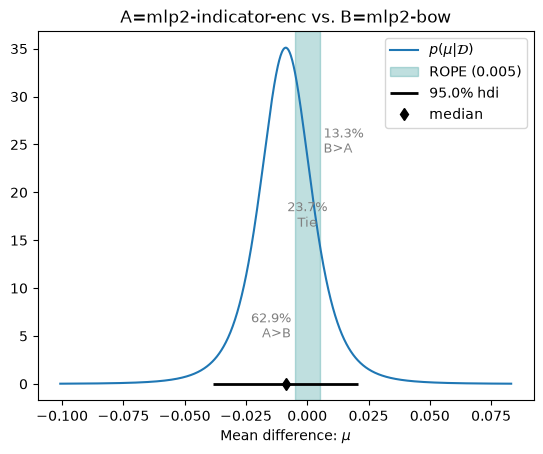

In [17]:
import analysis

# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([fold["metrics"][fold["best_epoch"]]["val_metrics"]["accuracy"] for fold in data[sys_name]])

posterior = analysis.BenavoliCorrelatedT(
    get_all_measurements_for(results, 'token-indicator'),  # this will have shape [num_runs * num_folds]
    get_all_measurements_for(results, 'bag-of-words'),  # this will have shape [num_runs * num_folds]
    names=["mlp2-indicator-enc", "mlp2-bow"]
)

p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005) 